# PPO - Super Mario Bros (World 1-1)

Pixels (84x84 grayscale, 4 stacked frames, frame skip 4) -> CNN actor-critic trained with PPO.
The environment is defined in `PPO/mario.py` (Gymnasium API on top of `gym-super-mario-bros`, patched for NumPy 2).

> Training is heavy: every environment runs in its own process. Keep `num_envs` low if the machine (or WSL) is short on RAM/CPU.

In [1]:
import torch
from PPO.PPO import PPO
from PPO.PPO import run_test_env
from PPO.mario import make_mario

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
Users of this version of Gym should be able to simply replace 'import gym' with 'import gymnasium as gym' in the vast majority of cases.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.


In [2]:
# HYPER-PARAMETERS #
max_frames       = int(1e7)
max_rewards      = None
num_steps        = 128
num_envs         = 16     # one process per env (~250 MB each): use 8 if WSL has the default ~8 GB cap
batch_size       = 512
ppo_epochs       = 4
lr               = 'lin_2.5e-4'
clip_range       = 'lin_0.2'
vf_coef          = 0.5
ent_coef         = 0.01
gamma            = 0.99
lam              = 0.95
clip_grad_norm   = 0.5
std_decay        = False  # discrete actions
clip_log_std     = None
log_every        = 25
runs_for_episode = 1
test_episodes    = 3
world, stage     = 1, 1
actions          = 'right_only'  # 'right_only' | 'simple' | 'complex'
log_file         = './logs/SuperMarioBros-1-1.pth'

In [3]:
def make_env():
    def _thunk():
        return make_mario(world=world, stage=stage, actions=actions)
    return _thunk

def make_test_env(render_mode=None):
    # unscaled reward (x progress, time and death penalty), as given by the game
    return make_mario(world=world, stage=stage, actions=actions, scale_reward=False, render_mode=render_mode)

obs_space: Box(0, 255, (4, 84, 84), uint8)
act_space: Discrete(5) ['NOOP', 'right', 'right+A', 'right+B', 'right+A+B']


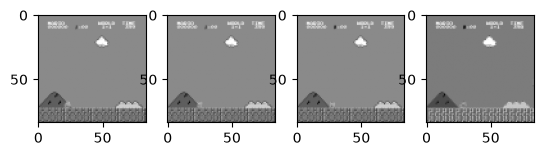

In [4]:
import matplotlib.pyplot as plt

env = make_env()()
print('obs_space:', env.observation_space)
print('act_space:', env.action_space, env.unwrapped.action_meanings)
obs, _ = env.reset()
for i in range(10):
    obs, r, terminated, truncated, _ = env.step(1)  # keep pressing 'right'
fig, axs = plt.subplots(1, 4)
for i in range(4):
    axs[i].imshow(obs[i], cmap='gray')
env.close()

In [ ]:
ppo = PPO(make_env, device='auto')

In [ ]:
# Run this cell to load a previous checkpoint
ppo.load(log_file)

In [ ]:
ppo.learn(max_frames, max_rewards=max_rewards, num_steps=num_steps, num_envs=num_envs, batch_size=batch_size,
          ppo_epochs=ppo_epochs, clip_range=clip_range, lr=lr, vf_coef=vf_coef, ent_coef=ent_coef,
          gamma=gamma, lam=lam, clip_grad_norm=clip_grad_norm, std_decay=std_decay, clip_log_std=clip_log_std,
          log_every=log_every, log_file=log_file, test_env=make_test_env(), runs_for_episode=runs_for_episode,
          test_episodes=test_episodes, tensorboard='./logs/tb/SuperMarioBros-1-1')

In [ ]:
del ppo

In [5]:
ppo = PPO(make_env, device='cpu')

In [6]:
ppo.load(log_file)

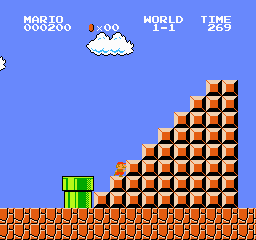

KeyboardInterrupt: 

In [9]:
env = make_test_env(render_mode='rgb_array')
runs_for_episode = 1
n_episode = 3

mean_reward = run_test_env(env=env, model=ppo, runs_for_episode=runs_for_episode, n_episodes=n_episode, vis=True, deterministic=True)
env.close()

print('Mean reward over %i episodes = %f' % (n_episode, mean_reward))